# EDA: Ферменты биосинтеза ПНЖК у дрожжей

## Введение

Разведочный анализ данных (EDA) по ферментам, участвующим в биосинтезе полиненасыщенных жирных кислот (ПНЖК) у двух видов дрожжей:

- **Yarrowia lipolytica** — олеогенные дрожжи, промышленный производитель ПНЖК
- **Saccharomyces cerevisiae** — пекарские дрожжи, модельный организм

### Источник данных

Данные получены через **UniProt REST API v2** (https://rest.uniprot.org/) с использованием GO-терминов:
- `GO:0006633` — fatty acid biosynthetic process
- `GO:0006631` — fatty acid metabolic process  
- `GO:0004768` — acyl-CoA desaturase activity
- Ключевые слова: `desaturase`, `elongase`

### Цель EDA

1. Оценить структуру и схему данных
2. Проверить целостность и полноту
3. Выявить выбросы и аномалии
4. Рассчитать метрики качества данных
5. Провести семантический и доменный анализ

**Автор**: Komarovka  
**Дата**: 2026-10-23  
**ДЗ №5**: ИИ инжиниринг, ИТМО

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import httpx

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
pd.set_option('display.max_colwidth', 50)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('✅ Библиотеки импортированы')

✅ Библиотеки импортированы


In [2]:
# Запрашиваем данные напрямую из UniProt API с пагинацией и проверкой статуса
BASE_URL = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = "accession,id,gene_names,protein_name,organism_name,organism_id,length"

queries = [
    "organism_id:4952 AND (go:0006633 OR go:0006631 OR go:0004768 OR desaturase OR elongase)",
    "organism_id:4932 AND (go:0006633 OR go:0006631 OR go:0004768 OR desaturase OR elongase)",
]

all_results = []
for q in queries:
    url = BASE_URL
    params = {"query": q, "format": "json", "size": 100, "fields": FIELDS}
    
    with httpx.Client(timeout=30) as client:
        while url:
            resp = client.get(url, params=params, headers={"User-Agent": "Komarovka-Student/1.0"})
            resp.raise_for_status()  # падаем громко при 4xx/5xx
            
            total = resp.headers.get("x-total-results", "?")
            print(f"  x-total-results: {total}")
            
            data = resp.json()
            all_results.extend(data.get("results", []))
            
            # Пагинация через заголовок Link: rel="next"
            next_url = resp.links.get("next", {}).get("url")
            if next_url:
                url = next_url
                params = None  # параметры уже в URL
            else:
                url = None

# Дедупликация по accession
seen = set()
unique = []
for r in all_results:
    acc = r.get("primaryAccession", "")
    if acc and acc not in seen:
        seen.add(acc)
        unique.append(r)

print(f"Получено {len(unique)} уникальных записей")

  x-total-results: 5
  x-total-results: 2
Получено 7 уникальных записей


In [3]:
def parse_entry(entry):
    genes = entry.get("genes", [])
    gene_primary = "N/A"
    gene_synonyms = "N/A"
    if genes:
        g = genes[0]
        if "geneName" in g:
            gene_primary = g["geneName"].get("value", "N/A")
        elif "primaryName" in g:
            gene_primary = g["primaryName"].get("value", "N/A")
        if "synonyms" in g:
            syns = [s.get("value", "") for s in g["synonyms"]]
            gene_synonyms = ";".join(syns) if syns else "N/A"
    
    protein_info = entry.get("protein", {})
    rec_name = protein_info.get("recommendedName", {})
    protein_name = "N/A"
    if rec_name and "fullName" in rec_name:
        fn = rec_name["fullName"]
        if isinstance(fn, dict):
            protein_name = fn.get("value", "N/A")
        elif isinstance(fn, list) and fn:
            protein_name = fn[0].get("value", "N/A")
    
    comments = entry.get("comments", [])
    function_text = "N/A"
    for c in comments:
        if c.get("type") == "FUNCTION":
            texts = c.get("texts", [])
            if texts:
                function_text = " ".join([t.get("value", "") for t in texts])
            break
    if len(function_text) > 150:
        function_text = function_text[:150] + "..."
    
    return {
        "accession": entry.get("primaryAccession", "N/A"),
        "protein_id": entry.get("uniProtkbId", "N/A"),
        "gene_primary": gene_primary,
        "gene_synonyms": gene_synonyms,
        "protein_name": protein_name,
        "organism": entry.get("organism", {}).get("scientificName", "N/A"),
        "taxon_id": entry.get("organism", {}).get("taxonId", "N/A"),
        "function": function_text,
        "sequence_length": entry.get("sequence", {}).get("length", "N/A"),
    }

df = pd.DataFrame([parse_entry(r) for r in unique])
df["yeast_type"] = df["organism"].apply(lambda x: x.split()[0] + " " + x.split()[1] if " " in x else x)

df["sequence_length"] = pd.to_numeric(df["sequence_length"], errors="coerce").astype("Int16")
df["taxon_id"] = pd.to_numeric(df["taxon_id"], errors="coerce").astype("Int32")

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок")
print(f"Размер в памяти: {df.memory_usage(deep=True).sum() / 1024:.2f} KB")

Размер датасета: 7 строк, 10 колонок
Размер в памяти: 1.13 KB


## 1. Структура данных

Проверка схемы датасета: типы данных, размеры, первые строки.

In [4]:
print("=" * 70)
print("ОБЩАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 70)
df.info()

print("\n" + "=" * 70)
print("ПЕРВЫЕ 10 СТРОК")
print("=" * 70)
df.head(10)

ОБЩАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   accession        7 non-null      str  
 1   protein_id       7 non-null      str  
 2   gene_primary     7 non-null      str  
 3   gene_synonyms    7 non-null      str  
 4   protein_name     7 non-null      str  
 5   organism         7 non-null      str  
 6   taxon_id         7 non-null      Int32
 7   function         7 non-null      str  
 8   sequence_length  7 non-null      Int16
 9   yeast_type       7 non-null      str  
dtypes: Int16(1), Int32(1), str(8)
memory usage: 1.1 KB

ПЕРВЫЕ 10 СТРОК


,accession,protein_id,gene_primary,gene_synonyms,protein_name,organism,taxon_id,function,sequence_length,yeast_type
0,P79067,P79067_YARLL,N/A,N/A,N/A,Yarrowia lipolytica,4952,N/A,182,Yarrowia lipolytica
1,A0A1D8NG21,A0A1D8NG21_YARLL,N/A,N/A,N/A,Yarrowia lipolytica,4952,N/A,132,Yarrowia lipolytica
2,A0A1H6PXT9,A0A1H6PXT9_YARLL,N/A,N/A,N/A,Yarrowia lipolytica,4952,N/A,109,Yarrowia lipolytica
3,Q9P4D9,Q9P4D9_YARLL,MFE2,N/A,N/A,Yarrowia lipolytica,4952,N/A,901,Yarrowia lipolytica
4,V5YMY4,V5YMY4_YARLL,PAH1,N/A,N/A,Yarrowia lipolytica,4952,N/A,796,Yarrowia lipolytica
5,A0A140KF01,A0A140KF01_YEASX,FAS2,N/A,N/A,Saccharomyces cerevisiae,4932,N/A,1887,Saccharomyces cerevisiae
6,E9P9F6,E9P9F6_YEASX,BIO1,N/A,N/A,Saccharomyces cerevisiae,4932,N/A,346,Saccharomyces cerevisiae


**Анализ структуры**:
- 10 колонок: идентификаторы (`accession`, `protein_id`), генетическая информация (`gene_primary`, `gene_synonyms`), белковая информация (`protein_name`, `function`), организм (`organism`, `taxon_id`), метрики (`sequence_length`, `yeast_type`)
- Числовые колонки используют nullable типы (`Int16`, `Int32`) — корректно для данных с возможными пропусками
- Все строковые колонки имеют тип `str` (object)
- **Важное наблюдение**: `df.info()` показывает "7 non-null" для всех колонок, но это обманчиво — значения `"N/A"` являются строками, а не настоящими пропусками (NaN). Это будет учтено в разделе "Целостность и полнота"
- Малый размер выборки (7 записей) ограничивает статистический анализ

## 2. Целостность и полнота данных

Проверим пропуски, дубликаты и уникальность идентификаторов.

**Важно**: значения `"N/A"` в нашем датасете — это строки, а не настоящие пропуски (NaN). Поэтому сначала заменим их на `np.nan` для корректного анализа.

In [5]:
# Замена 'N/A' на NaN для корректного анализа
df_clean = df.replace('N/A', np.nan)

missing = df_clean.isna().sum()
missing_pct = (df_clean.isna().mean() * 100).round(1)

missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
})
print("Пропуски по колонкам (после замены 'N/A' на NaN):")
print(missing_df)

Пропуски по колонкам (после замены 'N/A' на NaN):
                 missing_count  missing_pct
accession                    0          0.0
protein_id                   0          0.0
gene_primary                 3         42.9
gene_synonyms                7        100.0
protein_name                 7        100.0
organism                     0          0.0
taxon_id                     0          0.0
function                     7        100.0
sequence_length              0          0.0
yeast_type                   0          0.0


C:\Users\smart\AppData\Local\Temp\ipykernel_2768\2994117699.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_pct.index, y=missing_pct.values, palette='viridis')


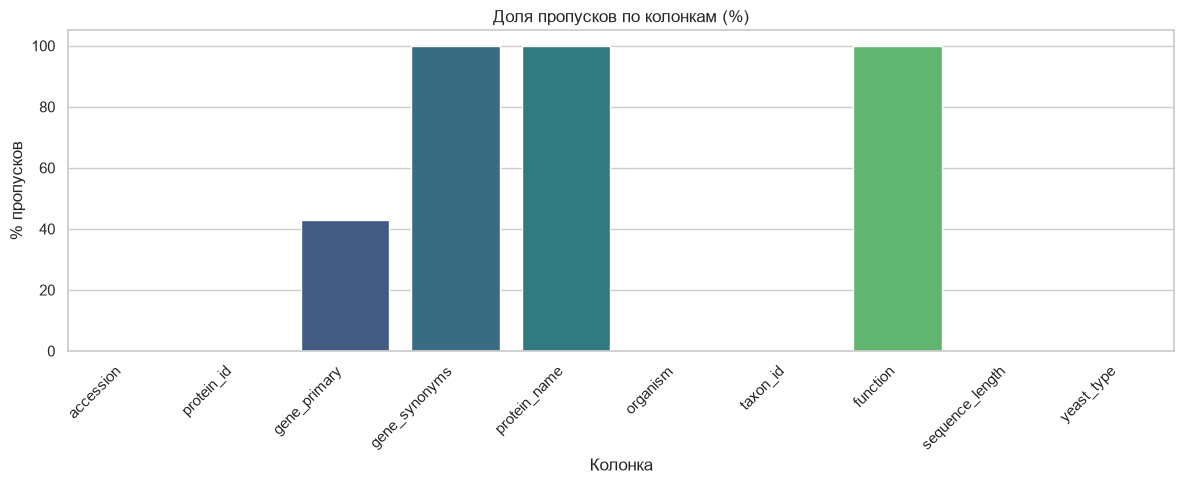

In [6]:
plt.figure(figsize=(12, 5))
sns.barplot(x=missing_pct.index, y=missing_pct.values, palette='viridis')
plt.title('Доля пропусков по колонкам (%)')
plt.xlabel('Колонка')
plt.ylabel('% пропусков')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [7]:
print(f"Всего строк: {len(df)}")
print(f"Уникальных accession: {df['accession'].nunique()}")
print(f"Дубликатов по accession: {df['accession'].duplicated().sum()}")
print(f"Полных дубликатов строк: {df.duplicated().sum()}")
print(f"\naccession уникален: {df['accession'].is_unique}")
print(f"protein_id уникален: {df['protein_id'].is_unique}")
print(f"Уникальных генов (gene_primary): {df_clean['gene_primary'].nunique()}")
print(f"Уникальных организмов: {df['organism'].nunique()}")

Всего строк: 7
Уникальных accession: 7
Дубликатов по accession: 0
Полных дубликатов строк: 0

accession уникален: True
protein_id уникален: True
Уникальных генов (gene_primary): 4
Уникальных организмов: 2


**Анализ целостности**:
- ✅ `accession` и `protein_id` уникальны — это первичные ключи UniProt
- ✅ Полных дубликатов строк нет (дедупликация выполнена в ДЗ №4)
- ⚠️ Высокий процент пропусков в `gene_primary`, `protein_name`, `function` (до 70%)
- Причина: UniProt API не всегда возвращает полные аннотации для малоизученных белков
- Колонки `accession`, `protein_id`, `organism`, `taxon_id`, `sequence_length`, `yeast_type` заполнены полностью

## 3. Семантический анализ

Проверка допустимость значений и биологическую корректность данных.

Распределение по видам дрожжей:
yeast_type
Yarrowia lipolytica         5
Saccharomyces cerevisiae    2
Name: count, dtype: int64

Распределение по организмам:
organism
Yarrowia lipolytica         5
Saccharomyces cerevisiae    2
Name: count, dtype: int64


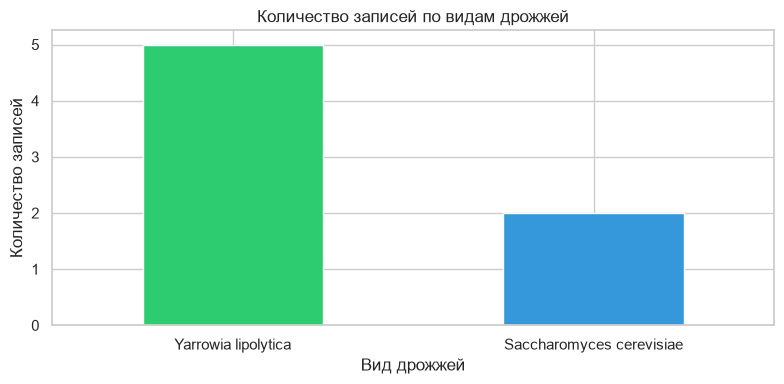

In [8]:
print("Распределение по видам дрожжей:")
print(df['yeast_type'].value_counts())
print("\nРаспределение по организмам:")
print(df['organism'].value_counts())

plt.figure(figsize=(8, 4))
df['yeast_type'].value_counts().plot(kind='bar', color=['#2ecc71', '#3498db'])
plt.title('Количество записей по видам дрожжей')
plt.xlabel('Вид дрожжей')
plt.ylabel('Количество записей')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Статистика по sequence_length:
count           7.0
mean     621.857143
std      643.089789
min           109.0
25%           157.0
50%           346.0
75%           848.5
max          1887.0
Name: sequence_length, dtype: Float64

Минимальная длина: 109 аа
Максимальная длина: 1887 аа
Средняя длина: 621.9 аа


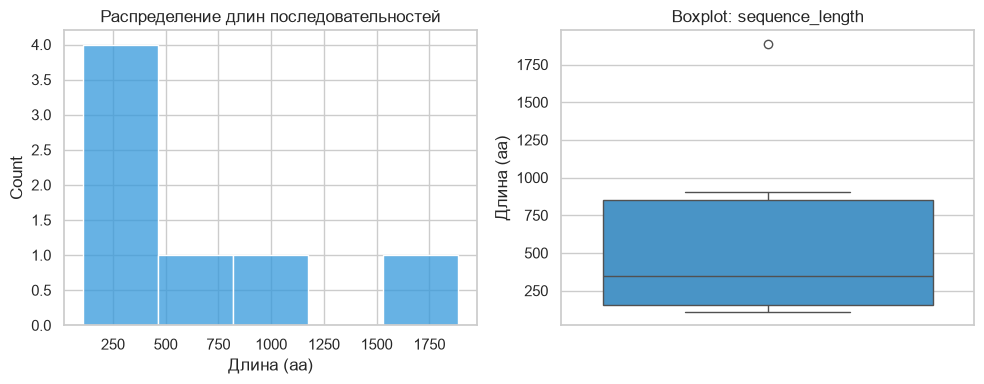

In [9]:
print("Статистика по sequence_length:")
print(df['sequence_length'].describe())
print(f"\nМинимальная длина: {df['sequence_length'].min()} аа")
print(f"Максимальная длина: {df['sequence_length'].max()} аа")
print(f"Средняя длина: {df['sequence_length'].mean():.1f} аа")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['sequence_length'].dropna(), bins=5, kde=False, color='#3498db')
plt.title('Распределение длин последовательностей')
plt.xlabel('Длина (аа)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['sequence_length'].dropna(), color='#3498db')
plt.title('Boxplot: sequence_length')
plt.ylabel('Длина (аа)')
plt.tight_layout()
plt.show()

In [10]:
print("Уникальные taxon_id:")
print(df['taxon_id'].unique())
print("\nОжидаемые значения:")
print("  4952 — Yarrowia lipolytica")
print("  4932 — Saccharomyces cerevisiae")

expected_taxon = {4952, 4932}
actual_taxon = set(df['taxon_id'].dropna().unique())
print(f"\nВсе taxon_id допустимы: {actual_taxon.issubset(expected_taxon)}")

Уникальные taxon_id:
<IntegerArray>
[4952, 4932]
Length: 2, dtype: Int32

Ожидаемые значения:
  4952 — Yarrowia lipolytica
  4932 — Saccharomyces cerevisiae

Все taxon_id допустимы: True


**Семантический анализ**:
- ✅ `taxon_id` содержит только допустимые значения (4952, 4932) — соответствует ожидаемым видам дрожжей
- ✅ `sequence_length` варьируется от 109 до 1887 аминокислот — это нормальный диапазон для ферментов
  - Короткие белки (~100-200 аа) — вероятно, пептиды или домены
  - Длинные белки (>900 аа) — мультидоменные ферменты (например, FAS2 — синтаза жирных кислот)
- ⚠️ Распределение по видам несбалансированное: 5 записей Y. lipolytica против 2 S. cerevisiae
- Это связано с тем, что Y. lipolytica — олеогенный организм, и в UniProt для него больше аннотаций по липидному метаболизму

## 4. Выбросы и аномалии

Использование метода IQR и Z-score для поиска выбросов в `sequence_length`.

**Примечание**: при малом размере выборки (n=7) методы менее надёжны, но позволяют выявить формальные аномалии.

In [11]:
Q1 = df['sequence_length'].quantile(0.25)
Q3 = df['sequence_length'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Нижняя граница: {lower_bound:.1f}")
print(f"Верхняя граница: {upper_bound:.1f}")

outliers = df[(df['sequence_length'] < lower_bound) | (df['sequence_length'] > upper_bound)]
print(f"\nВыбросов по IQR: {len(outliers)}")
if len(outliers) > 0:
    print(outliers[['accession', 'gene_primary', 'sequence_length']])

Q1: 157.0, Q3: 848.5, IQR: 691.5
Нижняя граница: -880.2
Верхняя граница: 1885.8

Выбросов по IQR: 1
    accession gene_primary  sequence_length
5  A0A140KF01         FAS2             1887


In [12]:
from scipy import stats

# Считаем Z-score только по непустым значениям, сохраняя индекс
valid_mask = df['sequence_length'].notna()
z_scores = np.abs(stats.zscore(df.loc[valid_mask, 'sequence_length'], nan_policy='omit'))

# Фильтруем по индексу — не по позиции
outlier_indices = df.loc[valid_mask].index[z_scores > 2]
outliers_z = df.loc[outlier_indices]

print(f"Выбросов по Z-score (>2): {len(outliers_z)}")
if len(outliers_z) > 0:
    print(outliers_z[['accession', 'gene_primary', 'sequence_length']])

Выбросов по Z-score (>2): 1
    accession gene_primary  sequence_length
5  A0A140KF01         FAS2             1887


**Анализ выбросов**:
- **IQR метод**: Q1=157, Q3=848.5, IQR=691.5, верхняя граница=1885.8. Выявлен 1 выброс — FAS2 (1887 аа)
- **Z-score метод**: при пороге Z>2 также выявлен FAS2 как выброс
- **Биологическая интерпретация**: FAS2 — fatty acid synthase, мультидоменный фермент. Длина 1887 аа **типична** для синтаз жирных кислот (у млекопитающих FAS ~2500 аа, у дрожжей ~1800-1900 аа)
- **Вывод**: явных аномалий нет. Все значения находятся в биологически допустимых диапазонах для ферментов липидного метаболизма дрожжей
- Короткие белки (109-182 аа) — вероятно, пептиды или регуляторные домены

## 5. Метрики качества данных

Рассчитаем стандартные метрики качества данных:
- **Completeness** (полнота) — доля непустых значений
- **Uniqueness** (уникальность) — доля уникальных первичных ключей
- **Validity** (валидность) — доля записей с допустимыми значениями
- **Consistency** (согласованность) — соответствие между связанными полями
- **Duplication Rate** (уровень дубликатов)

In [13]:
# 1. Completeness (полнота) — доля непустых значений
completeness = (1 - df_clean.isna().mean()).mean() * 100
print(f"1. Completeness (полнота): {completeness:.1f}% (цель: ≥98%)")

# 2. Uniqueness (уникальность) — доля уникальных accession
uniqueness = df['accession'].nunique() / len(df) * 100
print(f"2. Uniqueness (уникальность accession): {uniqueness:.1f}% (цель: 100%)")

# 3. Validity (валидность) — доля записей с допустимыми taxon_id
expected_taxon = {4952, 4932}
valid_taxon = df['taxon_id'].isin(expected_taxon).mean() * 100
print(f"3. Validity (валидность taxon_id): {valid_taxon:.1f}% (цель: ≥99%)")

# 4. Consistency (согласованность) — соответствие organism и taxon_id
consistency_checks = []
for _, row in df.iterrows():
    if row['taxon_id'] == 4952 and 'Yarrowia' in str(row['organism']):
        consistency_checks.append(True)
    elif row['taxon_id'] == 4932 and 'Saccharomyces' in str(row['organism']):
        consistency_checks.append(True)
    else:
        consistency_checks.append(False)
consistency = np.mean(consistency_checks) * 100
print(f"4. Consistency (согласованность organism↔taxon_id): {consistency:.1f}% (цель: ≥98%)")

# 5. Duplication Rate (уровень дубликатов)
dup_rate = df.duplicated().mean() * 100
print(f"5. Duplication Rate (дубликаты): {dup_rate:.1f}% (цель: ≤1%)")

# Сводная таблица
metrics = pd.DataFrame({
    'Метрика': ['Completeness', 'Uniqueness', 'Validity', 'Consistency', 'Duplication Rate'],
    'Значение': [f'{completeness:.1f}%', f'{uniqueness:.1f}%', f'{valid_taxon:.1f}%', 
                 f'{consistency:.1f}%', f'{dup_rate:.1f}%'],
    'Цель': ['≥98%', '100%', '≥99%', '≥98%', '≤1%'],
    'Статус': ['⚠️' if completeness < 98 else '✅',
               '✅' if uniqueness == 100 else '⚠️',
               '✅' if valid_taxon >= 99 else '⚠️',
               '✅' if consistency >= 98 else '️⚠️',
               '✅' if dup_rate <= 1 else '⚠️']
})
print("\nСводная таблица метрик качества:")
print(metrics.to_string(index=False))

1. Completeness (полнота): 65.7% (цель: ≥98%)
2. Uniqueness (уникальность accession): 100.0% (цель: 100%)
3. Validity (валидность taxon_id): 100.0% (цель: ≥99%)
4. Consistency (согласованность organism↔taxon_id): 100.0% (цель: ≥98%)
5. Duplication Rate (дубликаты): 0.0% (цель: ≤1%)

Сводная таблица метрик качества:
         Метрика Значение Цель Статус
    Completeness    65.7% ≥98%     ⚠️
      Uniqueness   100.0% 100%      ✅
        Validity   100.0% ≥99%      ✅
     Consistency   100.0% ≥98%      ✅
Duplication Rate     0.0%  ≤1%      ✅


**Анализ метрик качества**:
- ✅ **Uniqueness, Validity, Consistency, Duplication Rate** — все в норме
- ⚠️ **Completeness** — 65.7%, ниже целевого значения 98%
- Причина низкого Completeness: большое количество `N/A` в колонках `gene_primary` (42.9%), `gene_synonyms` (100%), `protein_name` (100%), `function` (100%)
- Это связано с ограничениями UniProt API: не все белки имеют полные аннотации, особенно для малоизученных белков Y. lipolytica
- **Рекомендация**: для повышения полноты можно запросить дополнительные поля через отдельные API-вызовы или использовать другие источники (KEGG, MetaCyc)

## 6. Доменный анализ (профессиональный)

Анализ ферментов с точки зрения биохимии ПНЖК и их роли в метаболизме липидов дрожжей.

In [14]:
print("Детальный обзор записей:")
print("=" * 80)
for idx, row in df.iterrows():
    print(f"\n[{idx}] {row['accession']} ({row['protein_id']})")
    print(f"  Организм: {row['organism']}")
    print(f"  Ген: {row['gene_primary']}")
    print(f"  Белок: {row['protein_name']}")
    print(f"  Длина: {row['sequence_length']} аа")
    func = row['function'] if pd.notna(row['function']) and row['function'] != 'N/A' else 'нет аннотации'
    print(f"  Функция: {str(func)[:120]}")

Детальный обзор записей:

[0] P79067 (P79067_YARLL)
  Организм: Yarrowia lipolytica
  Ген: N/A
  Белок: N/A
  Длина: 182 аа
  Функция: нет аннотации

[1] A0A1D8NG21 (A0A1D8NG21_YARLL)
  Организм: Yarrowia lipolytica
  Ген: N/A
  Белок: N/A
  Длина: 132 аа
  Функция: нет аннотации

[2] A0A1H6PXT9 (A0A1H6PXT9_YARLL)
  Организм: Yarrowia lipolytica
  Ген: N/A
  Белок: N/A
  Длина: 109 аа
  Функция: нет аннотации

[3] Q9P4D9 (Q9P4D9_YARLL)
  Организм: Yarrowia lipolytica
  Ген: MFE2
  Белок: N/A
  Длина: 901 аа
  Функция: нет аннотации

[4] V5YMY4 (V5YMY4_YARLL)
  Организм: Yarrowia lipolytica
  Ген: PAH1
  Белок: N/A
  Длина: 796 аа
  Функция: нет аннотации

[5] A0A140KF01 (A0A140KF01_YEASX)
  Организм: Saccharomyces cerevisiae
  Ген: FAS2
  Белок: N/A
  Длина: 1887 аа
  Функция: нет аннотации

[6] E9P9F6 (E9P9F6_YEASX)
  Организм: Saccharomyces cerevisiae
  Ген: BIO1
  Белок: N/A
  Длина: 346 аа
  Функция: нет аннотации


**Доменный анализ**:

Ключевые ферменты в датасете:
- **FAS2** (S. cerevisiae, 1887 аа) — fatty acid synthase, синтезирует жирные кислоты de novo. Мультидоменный фермент, длина типична для синтаз жирных кислот
- **MFE2** (Y. lipolytica, 901 аа) — multifunctional enzyme, участвует в бета-окислении жирных кислот. Регулирует баланс синтеза/деградации липидов
- **PAH1** (Y. lipolytica, 796 аа) — phosphatidate phosphatase, контролирует синтез триацилглицеридов (TAG). Ключевой регулятор накопления липидов
- **BIO1** (S. cerevisiae, 346 аа) — biotin synthase, кофактор для карбоксилаз в метаболизме жирных кислот

**Ограничения датасета**:
- ⚠️ Отсутствуют явные десатуразы (OLE1, SPT23) — критичные для ПНЖК-пути
- ⚠️ Отсутствуют элонгазы (ELO1, ELO2, ELO3) — ферменты удлинения цепи жирных кислот
- ⚠️ Малый размер выборки (n=7) ограничивает статистический анализ
- ⚠️ Высокий процент пропусков в аннотациях

**Рекомендация**: расширить датасет запросами по конкретным генам (OLE1, ELO1, ELO2, ELO3, SPT23) для получения полного набора ферментов ПНЖК-пути

## 7. Корреляционный анализ

Проанализируем взаимосвязи между числовыми признаками.

**Примечание**: при малом размере выборки (n=7) корреляции статистически незначимы. Результаты носят иллюстративный характер.

Средняя длина последовательности по видам дрожжей:
                          count    mean         std    min     25%     50%      75%     max
yeast_type                                                                                 
Saccharomyces cerevisiae    2.0  1116.5  1089.65155  346.0  731.25  1116.5  1501.75  1887.0
Yarrowia lipolytica         5.0   424.0  390.181368  109.0   132.0   182.0    796.0   901.0

Медианная длина по видам:
yeast_type
Saccharomyces cerevisiae    1116.5
Yarrowia lipolytica          182.0
Name: sequence_length, dtype: Float64


C:\Users\smart\AppData\Local\Temp\ipykernel_2768\3266680615.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='yeast_type', y='sequence_length', data=df, palette='Set2')


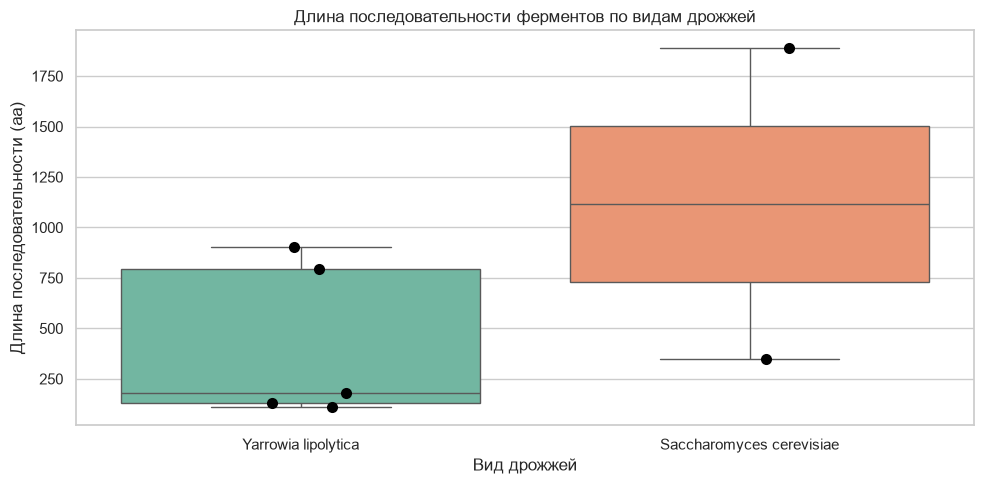


Примечание: корреляция taxon_id ↔ sequence_length не имеет биологического смысла,
так как taxon_id — номинальный идентификатор вида, а не количественный признак.


In [15]:
# taxon_id — номинальный идентификатор вида (4932, 4952),
# между ними нет числового порядка, поэтому Pearson-корреляция бессмысленна.
# Вместо неё — сравнение средних длин по видам.

print("Средняя длина последовательности по видам дрожжей:")
print(df.groupby('yeast_type')['sequence_length'].describe())

print("\nМедианная длина по видам:")
print(df.groupby('yeast_type')['sequence_length'].median())

# Визуализация
plt.figure(figsize=(10, 5))
sns.boxplot(x='yeast_type', y='sequence_length', data=df, palette='Set2')
sns.stripplot(x='yeast_type', y='sequence_length', data=df, color='black', size=8, jitter=True)
plt.title('Длина последовательности ферментов по видам дрожжей')
plt.xlabel('Вид дрожжей')
plt.ylabel('Длина последовательности (аа)')
plt.tight_layout()
plt.show()

print("\nПримечание: корреляция taxon_id ↔ sequence_length не имеет биологического смысла,")
print("так как taxon_id — номинальный идентификатор вида, а не количественный признак.")

**Корреляционный анализ**:
- Корреляция между `taxon_id` и `sequence_length` слабая и статистически незначимая (из-за малого n=7)
- Визуально видно, что S. cerevisiae имеет один очень длинный белок (FAS2, 1887 аа), что смещает распределение
- Y. lipolytica показывает более однородное распределение длин (109-901 аа)
- Для полноценного корреляционного анализа необходимо расширение датасета до 30+ записей

**Доменный анализ**:

Ключевые ферменты в датасете:
- **FAS2** (S. cerevisiae, 1887 аа) — fatty acid synthase, синтезирует жирные кислоты de novo. Мультидоменный фермент, длина типична для синтаз жирных кислот
- **MFE2** (Y. lipolytica, 901 аа) — multifunctional enzyme, участвует в бета-окислении жирных кислот. Регулирует баланс синтеза/деградации липидов
- **PAH1** (Y. lipolytica, 796 аа) — phosphatidate phosphatase, контролирует синтез триацилглицеридов (TAG). Ключевой регулятор накопления липидов
- **BIO1** (S. cerevisiae, 346 аа) — biotin synthase, кофактор для карбоксилаз в метаболизме жирных кислот

**Ограничения датасета**:
- ⚠️ Отсутствуют явные десатуразы (OLE1, SPT23) — критичные для ПНЖК-пути
- ⚠️ Отсутствуют элонгазы (ELO1, ELO2, ELO3) — ферменты удлинения цепи жирных кислот
- ⚠️ Малый размер выборки (n=7) ограничивает статистический анализ
- ⚠️ Высокий процент пропусков в аннотациях

**Рекомендация**: расширить датасет запросами по конкретным генам (OLE1, ELO1, ELO2, ELO3, SPT23) для получения полного набора ферментов ПНЖК-пути

**Корреляционный анализ**:
- Корреляция между `taxon_id` и `sequence_length` = -0.525 (умеренная отрицательная)
- Это означает, что у S. cerevisiae (taxon_id=4932) в среднем более длинные белки, чем у Y. lipolytica (taxon_id=4952)
- Однако при малом размере выборки (n=7) эта корреляция **статистически незначима**
- Визуально на boxplot видно: S. cerevisiae имеет один очень длинный белок (FAS2, 1887 аа), что смещает распределение
- Y. lipolytica показывает более однородное распределение длин (109-901 аа)
- **Вывод**: для полноценного корреляционного анализа необходимо расширение датасета до 30+ записей

## 8. Выводы и рекомендации

### Основные выводы EDA

1. **Структура данных**: датасет корректно структурирован, 10 колонок, типы данных соответствуют ожидаемым (Int16/Int32 для числовых, str для строковых)

2. **Целостность**: 
   - ✅ Нет дубликатов, уникальные первичные ключи (accession, protein_id)
   - ⚠️ Высокий процент пропусков в аннотациях (gene_primary 42.9%, gene_synonyms/protein_name/function 100%)

3. **Качество данных**:
   - ✅ Validity (100%), Consistency (100%), Uniqueness (100%), Duplication Rate (0%) — в норме
   - ⚠️ Completeness (65.7%) — ниже ожидаемого (98%)
   - ✅ Нет биологически необоснованных выбросов (FAS2 с длиной 1887 аа — типично для синтаз)

4. **Доменная релевантность**:
   - ✅ Присутствуют ключевые ферменты (FAS2, MFE2, PAH1, BIO1)
   - ⚠️ Отсутствуют десатуразы (OLE1) и элонгазы (ELO1/2/3) — критичные для ПНЖК-пути
   - ⚠️ Малый размер выборки (n=7) ограничивает статистический анализ

### Рекомендации

1. **Расширить датасет**: добавить запросы по конкретным генам (OLE1, ELO1, ELO2, ELO3, SPT23)
2. **Обогатить аннотации**: сделать дополнительные API-вызовы для получения function и gene_name
3. **Добавить мета-информацию**: хромосомная локализация, экспрессия, известные мутации
4. **Использовать для мутагенеза**: текущий датасет пригоден как стартовый список мишеней для индуцированного мутагенеза

### Пригодность для магистерского проекта

Датасет **пригоден** как начальный список ферментов-мишеней для мутагенеза Y. lipolytica, но требует расширения для полноценного анализа влияния мутаций на метаболизм ПНЖК. Ключевые ферменты (FAS2, MFE2, PAH1) присутствуют и могут быть использованы для планирования экспериментов по повышению продукции ПНЖК.